# 01 · Exploratory analysis and data quality

SokoRadar capstone. Inputs are the tables written by `python -m sokoradar.pipeline run --stages prepare`: cleaned WFP prices, the expanding-window ALPS, county climate and macro drivers. Shaded bands mark the 2010-11, 2016-17 and 2021-23 droughts.

In [1]:
import json, sys, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 10})
PROC, STORE, FIG = ROOT / "data/processed", ROOT / "data/store", ROOT / "reports/figures"
FIG.mkdir(parents=True, exist_ok=True)
PHASE_COLORS = {"Normal": "#2e7d32", "Stress": "#f2b705", "Alert": "#e8590c", "Crisis": "#c92a2a"}
DROUGHTS = [("2010-10-01", "2011-09-01"), ("2016-10-01", "2017-08-01"), ("2021-10-01", "2023-03-01")]
def shade(ax):
    for a, b in DROUGHTS:
        ax.axvspan(pd.Timestamp(a), pd.Timestamp(b), color="#c92a2a", alpha=0.07, lw=0)
metrics = json.loads((STORE / "metrics.json").read_text())


## Data quality

In [2]:
q = json.loads((STORE / "data_quality.json").read_text())
pd.Series({k: v for k, v in q.items() if k not in ("merged_pairs", "markets_without_county")}).to_frame("value")

,value
raw_rows,28463
raw_markets,226
raw_commodities,51
raw_period,2006-01 to 2026-09
rows_in_scope,9521
rows_unit_unparsed,0
markets_merged,6
series_before_filter,625
outliers_dropped,3
series_kept,67


In [3]:
prices = pd.read_parquet(PROC / "prices.parquet"); markets = pd.read_parquet(PROC / "markets.parquet")
series = pd.read_parquet(PROC / "series.parquet")
print(f"{prices.series_id.nunique()} series, {len(prices):,} monthly prices, {prices.market_key.nunique()} markets")
series.groupby(["commodity", "pricetype", "asal"]).agg(series=("series_id", "count"), median_obs=("n_obs", "median"),
                                                     median_coverage=("coverage", "median"))

67 series, 5,386 monthly prices, 30 markets


series  median_obs  median_coverage
commodity   pricetype asal                                          
beans       Retail    arid           13        52.0           0.7460
                      semi-arid       3        71.0           0.9860
            Wholesale non-ASAL        5       168.0           0.9820
goat_meat   Retail    arid            5        45.0           0.6720
maize       Retail    arid           17        53.0           0.7650
                      semi-arid       3        71.0           0.9860
            Wholesale non-ASAL        8       166.0           0.8805
                      semi-arid       1        38.0           0.6030
maize_flour Retail    arid           12        51.5           0.7335

### Coverage: which series have prices in which years

The long series (2006-2020) are the large wholesale markets and a few ASAL retail markets; refugee-camp markets in Turkana and Garissa start in 2021. Gaps are never filled in the target.

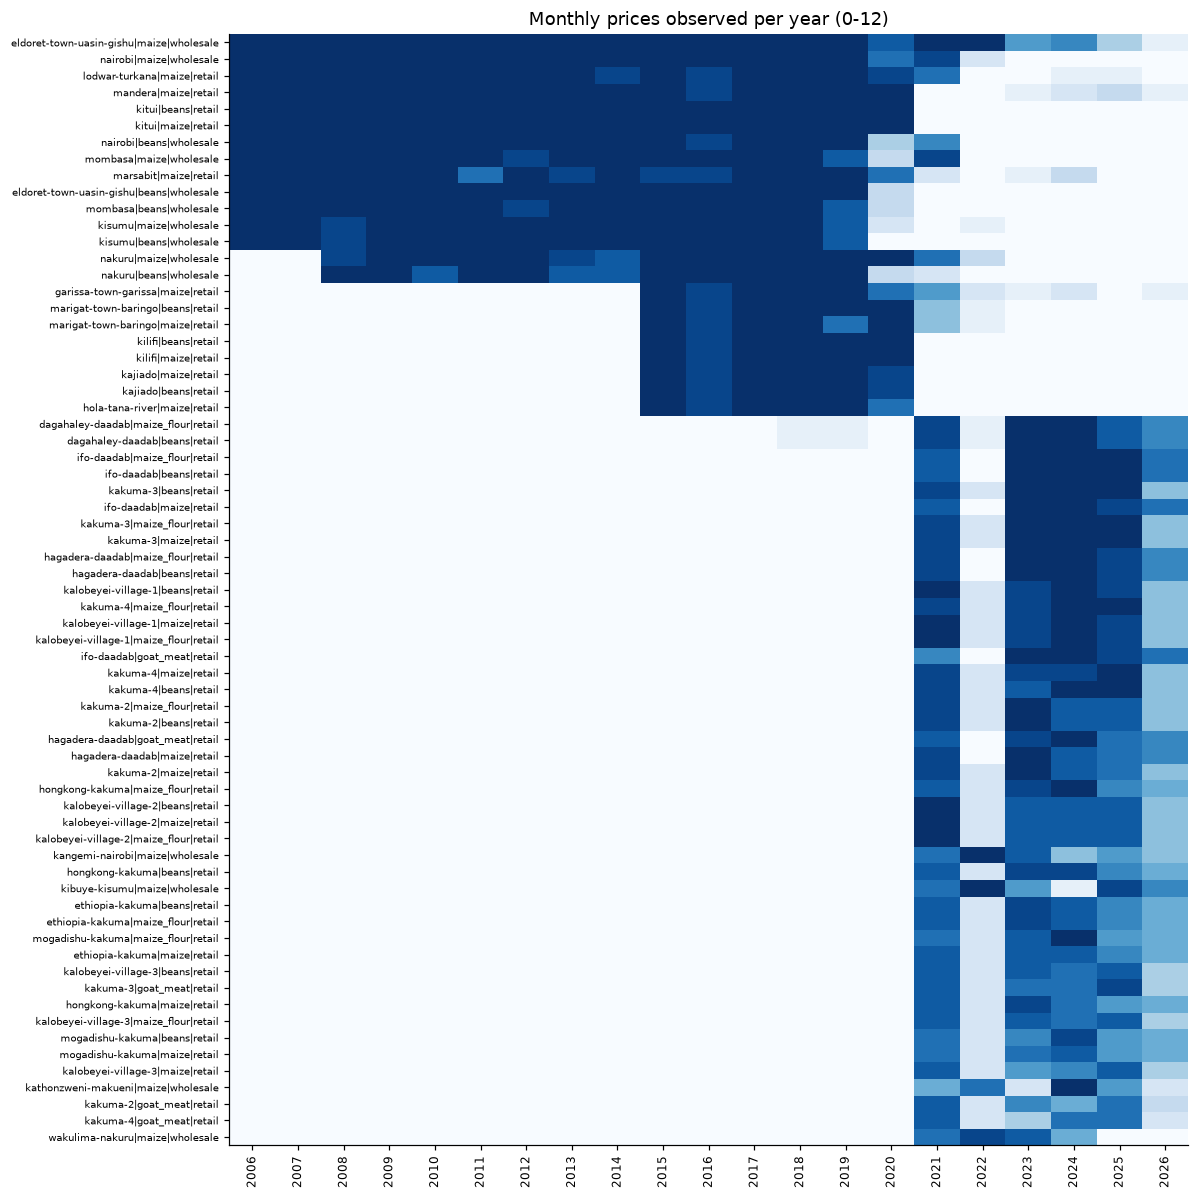

In [4]:
cov = prices.assign(year=prices.month.dt.year).pivot_table(index="series_id", columns="year", values="price",
                                                          aggfunc="count").fillna(0)
cov = cov.loc[cov.sum(axis=1).sort_values(ascending=False).index]
fig, ax = plt.subplots(figsize=(11, 11))
ax.imshow(cov.values, aspect="auto", cmap="Blues", vmin=0, vmax=12)
ax.set_yticks(range(len(cov))); ax.set_yticklabels(cov.index, fontsize=6.5)
ax.set_xticks(range(len(cov.columns))); ax.set_xticklabels(cov.columns, rotation=90, fontsize=8)
ax.set_title("Monthly prices observed per year (0-12)"); ax.grid(False)
fig.tight_layout(); fig.savefig(FIG / "coverage.png", bbox_inches="tight")

## Price histories

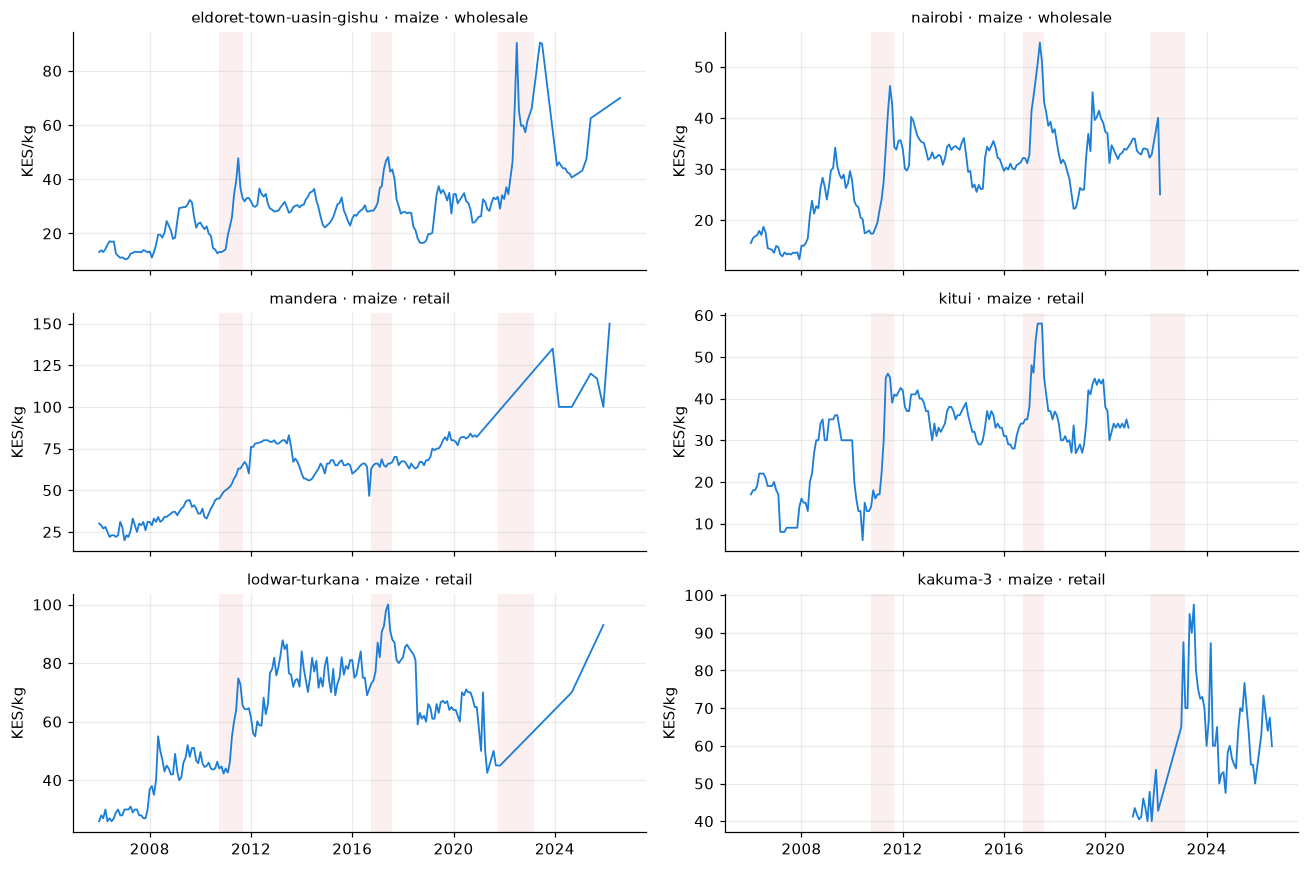

In [5]:
show = ["eldoret-town-uasin-gishu|maize|wholesale", "nairobi|maize|wholesale", "mandera|maize|retail",
        "kitui|maize|retail", "lodwar-turkana|maize|retail", "kakuma-3|maize|retail"]
fig, axes = plt.subplots(3, 2, figsize=(12, 8), sharex=True)
for ax, sid in zip(axes.flat, show):
    s = prices[prices.series_id == sid]
    ax.plot(s.month, s.price, lw=1.2, color="#1c7ed6"); shade(ax)
    ax.set_title(sid.replace("|", " · "), fontsize=10); ax.set_ylabel("KES/kg")
fig.tight_layout(); fig.savefig(FIG / "price_histories.png", bbox_inches="tight")

## Seasonality

Average deviation of log price from its 12-month centred mean, by calendar month. Wholesale maize in the grain basket falls with the Oct-Dec long-rains harvest and peaks before it; ASAL retail markets show a weaker, flatter cycle.

group,"Retail, arid","Retail, semi-arid",Wholesale (high-potential & cities)
month,,,
1,0.0,-0.1,-6.7
2,-2.5,-1.3,-4.6
3,2.0,-5.7,-3.3
4,0.0,-2.3,2.3
5,2.4,3.8,8.7
6,1.7,0.5,10.9
7,2.7,3.9,10.1
8,1.5,0.8,4.1
9,-2.5,-1.0,-1.4


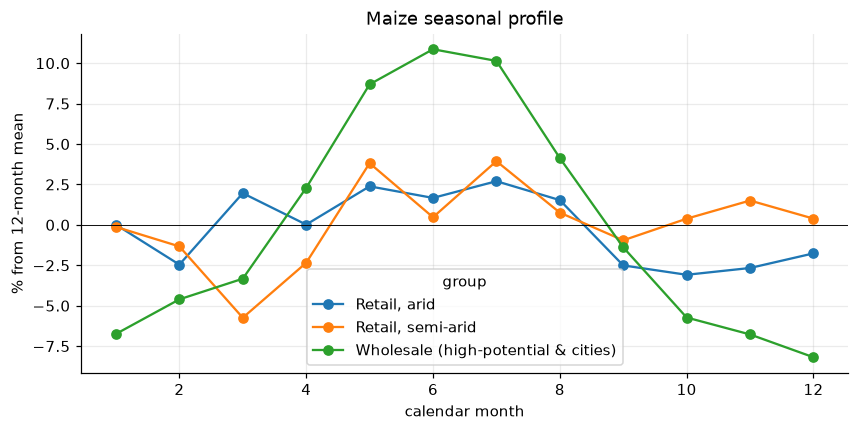

In [6]:
p = prices.sort_values(["series_id", "month"]).copy()
p["lp"] = np.log(p.price)
p["dev"] = p.lp - p.groupby("series_id").lp.transform(lambda s: s.rolling(13, center=True, min_periods=9).mean())
p = p.merge(markets[["market_key", "asal"]], on="market_key")
p["group"] = np.where(p.pricetype == "Wholesale", "Wholesale (high-potential & cities)", "Retail, " + p.asal)
seas = p[p.commodity == "maize"].groupby(["group", p.month.dt.month]).dev.mean().unstack(0) * 100
ax = seas.plot(figsize=(9, 4), marker="o"); ax.axhline(0, color="k", lw=0.6)
ax.set_xlabel("calendar month"); ax.set_ylabel("% from 12-month mean"); ax.set_title("Maize seasonal profile")
plt.savefig(FIG / "seasonality.png", bbox_inches="tight"); seas.round(1)

## ALPS phases over time

Share of observed market-months in each phase, computed without look-ahead. The 2011, 2017 and 2022 crises stand out.

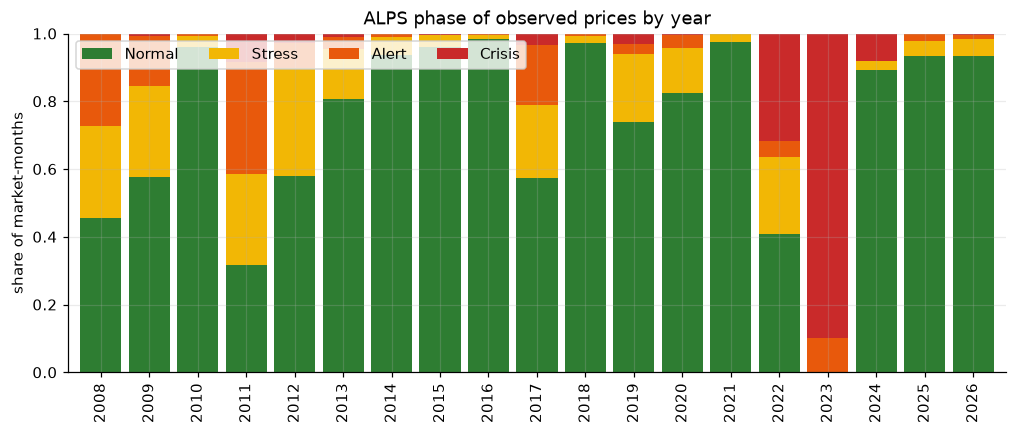

In [7]:
alps = pd.read_parquet(PROC / "alps.parquet")
share = alps.groupby([alps.month.dt.year, "phase"]).size().unstack(fill_value=0)
share = share.div(share.sum(axis=1), axis=0)[["Normal", "Stress", "Alert", "Crisis"]]
ax = share.plot.bar(stacked=True, figsize=(11, 4), color=[PHASE_COLORS[c] for c in share.columns], width=0.85)
ax.set_ylabel("share of market-months"); ax.set_xlabel(""); ax.legend(ncol=4, loc="upper left")
ax.set_title("ALPS phase of observed prices by year")
plt.savefig(FIG / "alps_by_year.png", bbox_inches="tight")

## Climate and prices

Rainfall over the previous three months against the maize price change over the next three months, by county type. In every county type drier seasons are followed by larger rises. The gradient is steepest where maize is grown (non-ASAL and semi-arid counties) and flatter in arid counties, whose markets are supplied from elsewhere.

mean  count
asal      rain_bin              
arid      <50        8.38     65
          50-75      2.98    213
          75-100     2.26    267
          100-125   -3.16    217
          125-150    1.01    130
          >150      -3.34    227
non-ASAL  <50       13.86     43
          50-75     10.03    167
          75-100     6.37    255
          100-125   -1.14    226
          125-150   -5.21    179
          >150      -6.20    111
semi-arid <50        9.49     15
          50-75      9.06     64
          75-100     5.27     89
          100-125    0.24     56
          125-150   -1.39     47
          >150      -8.70     63

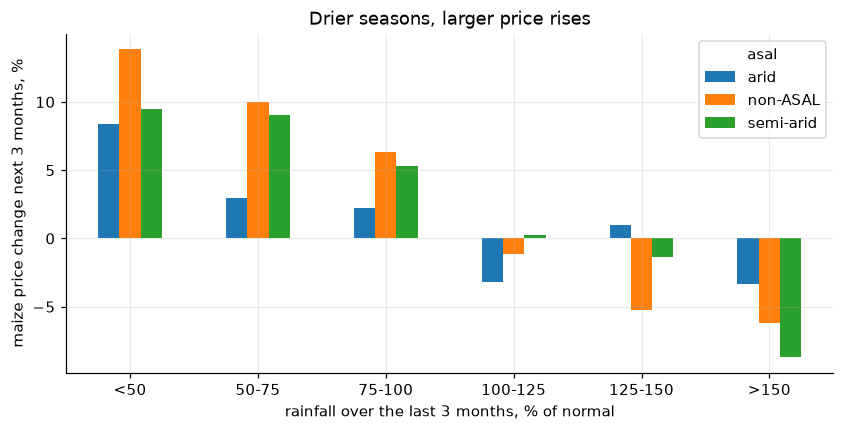

In [8]:
panel = pd.read_parquet(PROC / "panel.parquet")
d = panel[panel.observed & panel.tgt_h3.notna() & panel.rain3_l0.notna() & (panel.commodity == "maize")].copy()
d["rain_bin"] = pd.cut(d.rain3_l0, [0, 50, 75, 100, 125, 150, 400], labels=["<50", "50-75", "75-100", "100-125",
                                                                          "125-150", ">150"])
t = d.groupby(["asal", "rain_bin"], observed=True).tgt_h3.agg(["mean", "count"])
t["mean"] = 100 * t["mean"]
ax = t["mean"].unstack(0).plot.bar(figsize=(9, 4))
ax.set_xlabel("rainfall over the last 3 months, % of normal"); ax.set_ylabel("maize price change next 3 months, %")
ax.set_title("Drier seasons, larger price rises"); plt.xticks(rotation=0)
plt.savefig(FIG / "rain_vs_price.png", bbox_inches="tight"); t.round(2)

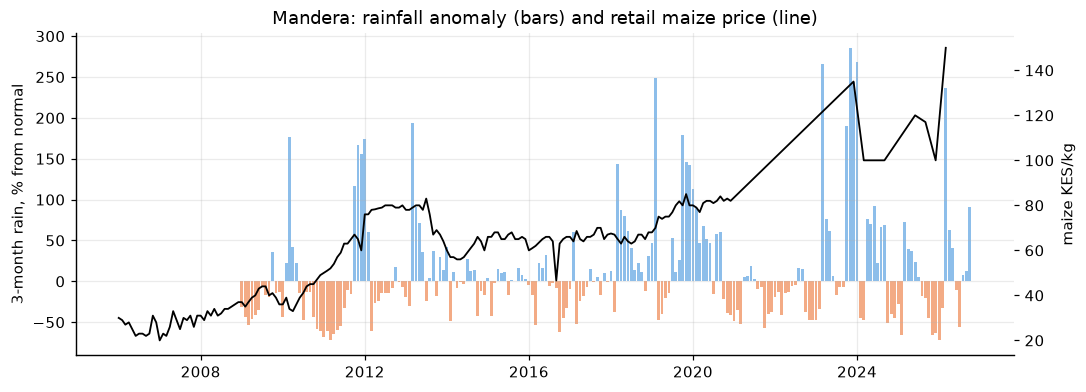

In [9]:
clim = pd.read_parquet(PROC / "climate.parquet")
m = clim[(clim.county_pcode == "KE009") & (clim.month >= "2009-01-01")]
s = prices[prices.series_id == "mandera|maize|retail"]
fig, ax = plt.subplots(figsize=(11, 3.8)); ax2 = ax.twinx()
ax.bar(m.month, m.rain_3m_pct - 100, width=25, color=np.where(m.rain_3m_pct < 100, "#e8590c", "#1c7ed6"), alpha=0.5)
ax2.plot(s.month, s.price, color="k", lw=1.2); ax.set_ylabel("3-month rain, % from normal"); ax2.set_ylabel("maize KES/kg")
ax.set_title("Mandera: rainfall anomaly (bars) and retail maize price (line)"); ax2.grid(False)
fig.savefig(FIG / "mandera_rain_price.png", bbox_inches="tight")

## Pastoral terms of trade

Kilograms of maize one goat buys (World Bank RTFP estimates for both prices).

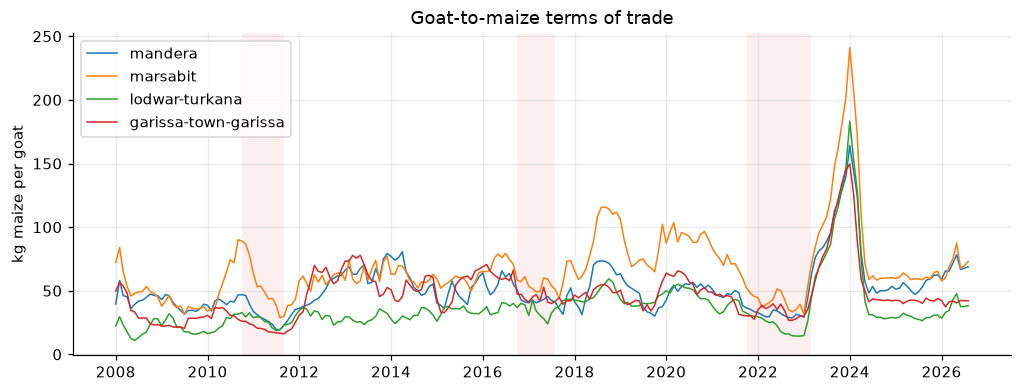

In [10]:
tot = pd.read_parquet(PROC / "tot.parquet")
fig, ax = plt.subplots(figsize=(11, 3.8))
for mk in ["mandera", "marsabit", "lodwar-turkana", "garissa-town-garissa"]:
    t = tot[(tot.market_key == mk) & (tot.month >= "2008-01-01")]
    ax.plot(t.month, t.tot_kg_per_goat, label=mk, lw=1)
shade(ax); ax.set_ylabel("kg maize per goat"); ax.legend(); ax.set_title("Goat-to-maize terms of trade")
fig.savefig(FIG / "terms_of_trade.png", bbox_inches="tight")

## Macro drivers

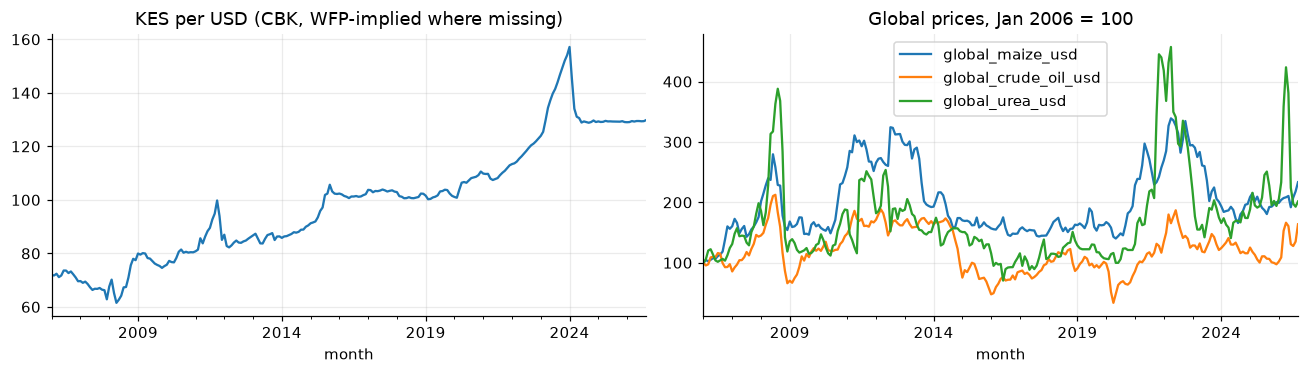

In [11]:
macro = pd.read_parquet(PROC / "macro.parquet")
macro = macro[macro.month >= "2006-01-01"].set_index("month")
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
macro.kes_usd.plot(ax=axes[0], title="KES per USD (CBK, WFP-implied where missing)")
(macro[["global_maize_usd", "global_crude_oil_usd", "global_urea_usd"]] /
 macro[["global_maize_usd", "global_crude_oil_usd", "global_urea_usd"]].iloc[0] * 100).plot(
    ax=axes[1], title="Global prices, Jan 2006 = 100")
fig.tight_layout()